# Monte Carlo Inference

Exact inference in a Bayesian network means summing the factors of the joint distribution over every variable that we do not care about. The cost of doing this grows rapidly with the size and connectivity of the network, and for networks containing continuous variables the sums become integrals that can rarely be evaluated in closed form. **Monte Carlo inference** takes a different approach: instead of calculating the answer, we *estimate* it from a large number of random samples drawn from the distribution. The name comes from the Monte Carlo casino in Monaco, and reflects the central role played by chance.

In this section we describe the idea in general, review the sampling methods that we met in the section on inference, and then introduce the idea of *Markov chain* Monte Carlo, which leads to the Gibbs sampler of the next section. Throughout we use the small network of the careers example, with Geography $G$, Mathematics $M$, Finance $F$ and Software development (programming) $S$, and the factorisation

$$P(G,M,F,S)=P(G)P(M)P(F\vert M)P(S\vert M)$$

We use the notation of the earlier sections: $P(F\vert M)$ is `PF_M`, an array indexed in the same order as its name, so that `PF_M[f][m]` is $P(F=f\vert M=m)$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

PG = np.array([0.6, 0.4])
PM = np.array([0.75, 0.25])
PF_M = np.array([[0.8, 0.4], [0.2, 0.6]])
PS_M = np.array([[0.65, 0.45], [0.35, 0.55]])

rng = np.random.default_rng(0)

## The basic idea

Suppose we can draw independent samples $x^{(1)},\dots,x^{(N)}$ from a distribution $P(X)$. Any probability can be written as the expected value of an *indicator function*, which is 1 when the event occurs and 0 otherwise:

$$
P(X\in A) = \mathbb{E}\left[\mathbb{1}(X\in A)\right] \approx \frac{1}{N}\sum_{i=1}^N \mathbb{1}\left(x^{(i)}\in A\right) = \frac{N_A}{N}
$$

where $N_A$ is the number of samples that fall in $A$. This is simply "count the outcomes and divide by the number of samples", exactly as we did to estimate the bias of a coin and to estimate $\pi$ by throwing random points at a square. More generally, the expected value of any function $f$ of the variables can be estimated by the sample average:

$$
\mathbb{E}[f(X)] \approx \frac{1}{N}\sum_{i=1}^N f\left(x^{(i)}\right)
$$

The **law of large numbers** guarantees that these estimates converge to the true values as $N\to\infty$. The **central limit theorem** tells us how quickly: the typical error of an estimate is proportional to $1/\sqrt{N}$. For a probability $p$ estimated from $N$ samples the standard error is $\sqrt{p(1-p)/N}$. Two features of this are worth remembering.

* Reducing the error by a factor of 10 requires 100 times as many samples.
* The error depends on $N$ and on $p$, but *not* on the number of variables in the problem. This is the reason why Monte Carlo methods remain usable when exact methods are not. However, estimating the probability of a rare event is expensive: to estimate a probability of $10^{-6}$ to within 10% we need of the order of $10^8$ samples.

The price we pay is that the answer is *approximate*, and it is random: two runs of the same algorithm will give slightly different answers. As an example, we estimate $P(F=1)=\sum_mP(F=1\vert M=m)P(M=m)=0.2\times0.75+0.6\times0.25=0.3$ five times, with $N=10{,}000$ samples each time.

In [ ]:
N = 10000
exact = (PF_M @ PM)[1]                           # P(F=1) by marginalisation
print(f"Exact P(F=1) = {exact:.4f},  standard error for N = {N}: {np.sqrt(exact*(1 - exact)/N):.4f}")
for run in range(5):
    M_ = rng.binomial(1, PM[1], N)               # sample M, then F given M
    F_ = rng.binomial(1, PF_M[1, M_])
    print(f"Run {run + 1}: estimate of P(F=1) = {F_.mean():.4f}")

Exact P(F=1) = 0.3000,  standard error for N = 10000: 0.0046
Run 1: estimate of P(F=1) = 0.2906
Run 2: estimate of P(F=1) = 0.2998
Run 3: estimate of P(F=1) = 0.3027
Run 4: estimate of P(F=1) = 0.2956
Run 5: estimate of P(F=1) = 0.2996


## Sampling from a Bayesian network

The factorisation of a Bayesian network gives us an easy way to draw samples from the full joint distribution. Because the network is a DAG we can order the variables so that every variable comes after its parents (a *topological ordering*). We then visit the variables in this order and, for each one, draw a value from its conditional probability distribution given the values already drawn for its parents. For the baking example this means sampling $H$ first, then $A$ and $T$ given $H$, then $R$ given $A$ and $T$, and so on; for the careers network we sample $G$ and $M$, then $F$ and $S$ given $M$. This is sometimes called *ancestral* or *forward* sampling, and is the direct sampling that we met earlier. Each pass through the network produces one complete sample from the joint distribution, and a collection of samples (a *trace*) can be used to estimate any marginal or conditional probability by counting.

In [ ]:
def sample_network(N):
    """N complete samples (G, M, F, S) from the network, as the rows of an array."""
    G = rng.binomial(1, PG[1], N)
    M_ = rng.binomial(1, PM[1], N)
    F_ = rng.binomial(1, PF_M[1, M_])         # F depends on M
    S_ = rng.binomial(1, PS_M[1, M_])         # S depends on M
    return np.column_stack([G, M_, F_, S_])

trace = sample_network(100000)
print("First rows of the trace (columns G, M, F, S):")
print(trace[:5])
print("Estimated P(M=1) =", trace[:, 1].mean(), "(exact 0.25)")

First rows of the trace (columns G, M, F, S):
[[1 0 1 0]
 [0 0 1 0]
 [0 0 0 1]
 [1 1 1 1]
 [1 1 1 0]]
Estimated P(M=1) = 0.25031 (exact 0.25)


## Conditioning on evidence

Usually we are interested in a *conditional* distribution $P(Q\vert E=e)$ of some *query* variables $Q$, given observed values $e$ of some *evidence* variables $E$. By the definition of conditional probability,

$$
P(Q=q\vert E=e)=\frac{P(Q=q,E=e)}{P(E=e)}\approx\frac{N_{q,e}}{N_e}
$$

where $N_e$ is the number of samples in which the evidence holds, and $N_{q,e}$ is the number of those in which the query also holds. There are three ways that this idea can be put to work.

1. **Rejection sampling.** Generate samples from the full joint distribution and discard those that do not agree with the evidence. This is correct, simple and flexible (the same trace can answer many different queries), but wasteful: the fraction of samples retained is $P(E=e)$, which becomes tiny when the evidence is unlikely or when there are many evidence variables.

2. **Likelihood weighting.** Fix the evidence variables to their observed values, sample only the non-evidence variables, and give each sample a *weight* equal to the product of the probabilities $P(E_j=e_j\vert\mathrm{parents}(E_j))$ of the evidence values given the sampled values of their parents. Every sample is used, but samples that make the evidence unlikely contribute little. Estimates are weighted counts. The weights can become dominated by a few samples when evidence is unlikely or lies deep in the network.

3. **Markov chain Monte Carlo (MCMC).** Rather than generating each sample independently from scratch, generate each new sample by making a small random change to the previous one. This is the subject of the rest of this section.

As an example, we estimate $P(M=1\vert F=0,S=1)$, the probability that someone who works in programming but not in finance studied mathematics, by the first two methods. By Bayes rule the exact answer is $P(F=0\vert M=1)P(S=1\vert M=1)P(M=1)/\sum_mP(F=0\vert M=m)P(S=1\vert M=m)P(M=m)$.

In [ ]:
# Exact answer by Bayes rule: P(M | F=0, S=1) is proportional to P(M) P(F=0|M) P(S=1|M)
unnormalised = PM * PF_M[0, :] * PS_M[1, :]
exact_post = unnormalised / unnormalised.sum()
print(f"Exact P(M=1 | F=0, S=1) = {exact_post[1]:.4f}   (probability of the evidence P(F=0, S=1) = {unnormalised.sum():.4f})")

N = 20000
# 1. Rejection sampling: keep the samples with F=0 and S=1
trace = sample_network(N)
keep = (trace[:, 2] == 0) & (trace[:, 3] == 1)
print(f"Rejection sampling:   {keep.sum()} of {N} samples kept, estimate = {trace[keep, 1].mean():.4f}")

# 2. Likelihood weighting: fix F=0 and S=1, sample M, weight by P(F=0|M) P(S=1|M)
M_ = rng.binomial(1, PM[1], N)
w = PF_M[0, M_] * PS_M[1, M_]
print(f"Likelihood weighting: effective sample size = {w.sum()**2 / (w**2).sum():.0f}, estimate = {(w * M_).sum() / w.sum():.4f}")

Exact P(M=1 | F=0, S=1) = 0.2075   (probability of the evidence P(F=0, S=1) = 0.2650)
Rejection sampling:   5343 of 20000 samples kept, estimate = 0.2057
Likelihood weighting: effective sample size = 19811, estimate = 0.2059


Rejection sampling and likelihood weighting both produce *independent* samples, but both can waste almost all of their effort when the evidence has low probability. Here the evidence is quite probable ($P(F=0,S=1)\approx0.27$) and so little is wasted. MCMC avoids the problem by spending its time where the posterior probability is high.

## Markov chain Monte Carlo

A **Markov chain** is a sequence of random states $s_1,s_2,s_3,\dots$ in which the next state depends only on the current state, and not on the earlier history:

$$
P(s_{t+1}\vert s_t,s_{t-1},\dots,s_1)=P(s_{t+1}\vert s_t)
$$

The probabilities $T(s\to s') = P(s_{t+1}=s'\vert s_t=s)$ are called the *transition probabilities*. In the notation we use in code, we store them in an array `PX1_X0[x1][x0]`, the probability of moving to state $x_1$ from state $x_0$, so that each *column* sums to 1.

As an example, suppose that the weather on any day is Sunny (0) or Rainy (1). If today is sunny, tomorrow is sunny with probability 0.9; if today is rainy, tomorrow is sunny with probability 0.5.

In [ ]:
PX1_X0 = np.array([[0.9, 0.5],       # P(sunny tomorrow | today),  columns: today sunny, rainy
                   [0.1, 0.5]])      # P(rainy tomorrow | today)

def run_chain(PX1_X0, x0, nsteps):
    """Simulate nsteps of the chain starting from state x0."""
    x = np.zeros(nsteps, dtype=int)
    x[0] = x0
    for t in range(1, nsteps):
        x[t] = rng.choice(2, p=PX1_X0[:, x[t - 1]])
    return x

for x0 in (0, 1):
    x = run_chain(PX1_X0, x0, 20000)
    print(f"Started in state {x0}: first 10 states {x[:10]},  fraction sunny = {np.mean(x == 0):.4f}")

Started in state 0: first 10 states [0 0 0 0 0 0 0 0 0 0],  fraction sunny = 0.8295


Started in state 1: first 10 states [1 1 1 1 1 1 1 1 0 0],  fraction sunny = 0.8294


Whichever state the chain starts in, the fraction of time spent in each state settles to the same values. Under mild conditions (every state can be reached from every other state, and the chain does not cycle with a fixed period) a Markov chain has a unique **stationary distribution** $\pi(s)$ with the property that if the state is distributed as $\pi$ at one step then it is distributed as $\pi$ at the next:

$$\pi(s')=\sum_s T(s\to s')\pi(s)$$

or, in code, `pi = PX1_X0 @ pi`. In other words $\pi$ is an eigenvector of the transition matrix with eigenvalue 1. Furthermore, wherever the chain starts, the fraction of time it spends in each state converges to $\pi(s)$.

Stationary distribution (sunny, rainy): [0.8333 0.1667]
Check pi = PX1_X0 @ pi: True


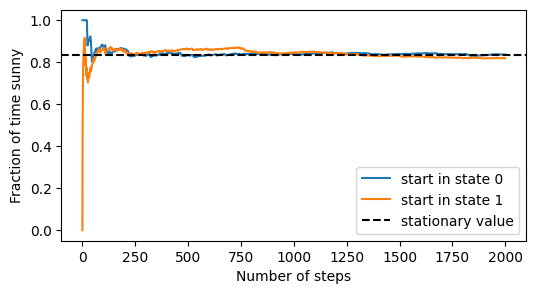

In [ ]:
# The stationary distribution is the eigenvector with eigenvalue 1, normalised to sum to 1
values, vectors = np.linalg.eig(PX1_X0)
pi = np.real(vectors[:, np.argmax(np.real(values))])
pi = pi / pi.sum()
print("Stationary distribution (sunny, rainy):", np.round(pi, 4))
print("Check pi = PX1_X0 @ pi:", np.allclose(pi, PX1_X0 @ pi))

# Running estimate of P(sunny) from two different starting states
fig, ax = plt.subplots(figsize=(6, 3))
for x0 in (0, 1):
    x = run_chain(PX1_X0, x0, 2000)
    ax.plot(np.cumsum(x == 0) / np.arange(1, 2001), label=f"start in state {x0}")
ax.axhline(pi[0], color='k', ls='--', label="stationary value")
ax.set_xlabel("Number of steps"); ax.set_ylabel("Fraction of time sunny"); ax.legend()
plt.show()

MCMC turns this around. We want to sample from a *target* distribution, the posterior $P(Q\vert E=e)$. We therefore *design* the transition probabilities so that the stationary distribution of the chain is the target distribution. If we do this, then running the chain for a long time and recording the states that it visits is equivalent to drawing samples from the posterior, and we can estimate probabilities by counting how often each state is visited, just as before. The key difference is that **successive samples are correlated** (each is a small modification of the previous one), so a chain of $N$ samples contains less information than $N$ independent samples; the *effective sample size* is smaller than $N$.

In summary, a typical MCMC calculation proceeds as follows.

1. Fix the evidence variables at their observed values.
2. Start the chain from an arbitrary state consistent with the evidence.
3. Repeatedly apply the transition rule to generate a sequence of states.
4. Discard an initial **burn-in** period during which the chain has not yet reached its stationary distribution.
5. Estimate the desired probabilities from the proportion of the remaining states that satisfy the condition of interest.

### Designing the chain: the Metropolis rule

How do we choose transition probabilities that have the target $\pi$ as their stationary distribution? One simple sufficient condition is *detailed balance*:

$$\pi(s)T(s\to s')=\pi(s')T(s'\to s)$$

If the chain satisfies this for every pair of states, then $\pi$ is stationary. The **Metropolis algorithm** builds a chain with this property in two steps. From the current state $s$:

1. *Propose* a new state $s'$ by making a small random change, in a way that is symmetric (the probability of proposing $s'$ from $s$ equals the probability of proposing $s$ from $s'$).
2. *Accept* the proposal with probability $\min\left(1,\ \pi(s')/\pi(s)\right)$; otherwise stay at $s$ (and count $s$ again).

Notice that only the *ratio* $\pi(s')/\pi(s)$ is needed, so we never need to compute the normalising constant $P(E=e)$ of the posterior, which is the expensive part of exact inference. For a Bayesian network the unnormalised posterior of a state is simply the joint distribution with the evidence variables fixed, and it is a product of the local conditional probabilities.

We apply this to the careers network with evidence $F=0$ and $S=1$. The state is $(G,M)$, the non-evidence variables, and the proposal flips one of the two variables, chosen at random.

The code below has three parts.

1. **The target, `unnormalised_posterior(g, m)`.** This returns the joint probability $P(G=g)P(M=m)P(F=0\vert M=m)P(S=1\vert M=m)$ with the evidence values `f_obs` and `s_obs` plugged in. It is not a probability distribution over $(G,M)$, because it does not sum to 1 (the sum is $P(F=0,S=1)$), but it is proportional to the posterior $P(G,M\vert F=0,S=1)$, and for the Metropolis rule that is all we need.

2. **One step of the chain, inside `metropolis`.** The variable `state` holds the current values `[G, M]`. Each pass through the loop:
   * copies the state into `proposal` and flips one randomly chosen entry (`1 - proposal[i]` turns 0 into 1 and 1 into 0). Choosing $G$ or $M$ with equal probability, and flipping rather than choosing a new value, makes the proposal symmetric as required;
   * computes `ratio`, the unnormalised posterior of the proposed state divided by that of the current state, so the unknown normalising constant cancels;
   * draws a uniform random number and accepts the proposal if it is less than `min(1, ratio)`. A move to a more probable state (`ratio` $\ge1$) is always accepted, and a move to a less probable one is accepted with probability equal to the ratio. If the move is rejected, `state` is unchanged and is recorded again;
   * stores the state in `trace`, so each row of `trace` is one sample $(G,M)$, and counts accepted moves so that we can report the acceptance rate.

3. **Running the chain.** We start from $(G,M)=(0,0)$, generate 50,000 steps, discard the first 1,000 as burn-in, and estimate each posterior probability as the mean of the corresponding column of the remaining samples (the fraction of samples in which that variable equals 1). Because $G$ is independent of $F$ and $S$, its posterior is just its prior, which gives a second check.

In [ ]:
f_obs, s_obs = 0, 1

def unnormalised_posterior(g, m):
    """P(G=g) P(M=m) P(F=f_obs | M=m) P(S=s_obs | M=m): the joint distribution with the evidence fixed."""
    return PG[g] * PM[m] * PF_M[f_obs, m] * PS_M[s_obs, m]

def metropolis(nsteps, state):
    trace = np.zeros((nsteps, 2), dtype=int)
    accepted = 0
    for t in range(nsteps):
        proposal = list(state)
        i = rng.integers(2)                       # choose G or M at random
        proposal[i] = 1 - proposal[i]             # and flip it (a symmetric proposal)
        ratio = unnormalised_posterior(*proposal) / unnormalised_posterior(*state)
        if rng.random() < min(1.0, ratio):        # accept with probability min(1, ratio)
            state = proposal
            accepted += 1
        trace[t] = state
    return trace, accepted / nsteps

nsteps, burn_in = 50000, 1000
trace, acceptance = metropolis(nsteps, [0, 0])
samples = trace[burn_in:]                         # discard the burn-in
print(f"Acceptance rate: {acceptance:.2f}")
print(f"Estimated P(M=1 | F=0, S=1) = {samples[:, 1].mean():.4f}   (exact {exact_post[1]:.4f})")
print(f"Estimated P(G=1 | F=0, S=1) = {samples[:, 0].mean():.4f}   (exact {PG[1]:.4f}, since G is independent of the evidence)")

Acceptance rate: 0.61
Estimated P(M=1 | F=0, S=1) = 0.2086   (exact 0.2075)
Estimated P(G=1 | F=0, S=1) = 0.3963   (exact 0.4000, since G is independent of the evidence)


The estimates agree well with the exact values. Because each state is a small change from the last, successive samples are correlated. We can measure this by the *autocorrelation* $\rho_k$ of the sequence at lag $k$ (the correlation between samples $k$ steps apart). The effective sample size is approximately $N/(1+2\sum_{k\ge1}\rho_k)$.

Number of samples: 49000,  effective sample size for M: 22435


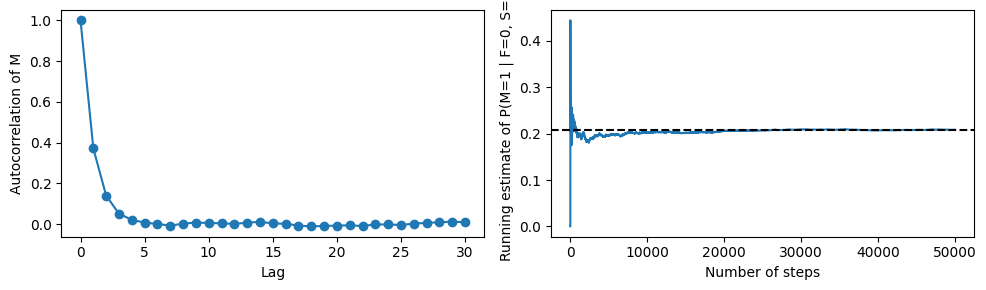

In [ ]:
def autocorrelation(x, maxlag=50):
    x = x - x.mean()
    n = len(x)
    acf = np.correlate(x, x, mode='full')[n - 1:n + maxlag] / (x.var() * n)
    return acf

def effective_sample_size(x, maxlag=200):
    acf = autocorrelation(x, maxlag)
    cutoff = np.argmax(acf < 0) if np.any(acf < 0) else len(acf)   # sum until the autocorrelation first goes negative
    tau = 1 + 2 * acf[1:cutoff].sum()
    return len(x) / tau

m = samples[:, 1].astype(float)
print(f"Number of samples: {len(m)},  effective sample size for M: {effective_sample_size(m):.0f}")

fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].plot(autocorrelation(m, 30), 'o-'); axs[0].set_xlabel("Lag"); axs[0].set_ylabel("Autocorrelation of M")
axs[1].plot(np.cumsum(trace[:, 1]) / np.arange(1, nsteps + 1))
axs[1].axhline(exact_post[1], color='k', ls='--'); axs[1].set_xlabel("Number of steps"); axs[1].set_ylabel("Running estimate of P(M=1 | F=0, S=1)")
plt.tight_layout(); plt.show()

The effective sample size is only about half the number of samples, which is the price paid for correlated samples (it can be far worse for more strongly coupled problems). The right-hand plot also shows the effect of the initial state: the running estimate starts away from the exact value and needs some time to settle, which is why we discard a burn-in period.

### Things that can go wrong

Because the answer comes from a single, long, correlated run, MCMC requires some care that independent sampling does not.

* **Convergence.** We cannot be sure that the chain has reached its stationary distribution. In practice we discard burn-in, run several chains from different starting points, and check that they agree.
* **Mixing.** If the target distribution has well-separated regions of high probability, the chain can become trapped in one of them for a very long time and give badly wrong answers without any obvious warning. We can see this with the weather chain by making the states very "sticky": if the chain almost never changes state, a run of a thousand steps may spend all, or most, of its time near the starting state even though the stationary distribution is 50:50.

In [ ]:
PX1_X0_sticky = np.array([[0.999, 0.001],
                          [0.001, 0.999]])     # stationary distribution is (0.5, 0.5)

for x0 in (0, 1):
    x = run_chain(PX1_X0_sticky, x0, 1000)
    print(f"Started in state {x0}: fraction of time in state 0 = {np.mean(x == 0):.3f}   (stationary value 0.5)")

Started in state 0: fraction of time in state 0 = 1.000   (stationary value 0.5)
Started in state 1: fraction of time in state 0 = 0.603   (stationary value 0.5)


## The Gibbs sampler

The Metropolis algorithm needs a *proposal* and rejects some of the proposed moves. For a Bayesian network we can do better, with a method that never rejects a move: the **Gibbs sampler**, named after the physicist Josiah Willard Gibbs, whose work in statistical thermodynamics has close parallels with (and significantly predates) this approach to random sampling. It is conceptually very simple.

* Fix all *evidence variables* to their observed values. These are not changed during sampling.
* Initialise all of the non-evidence variables to values supported by their distributions. There are no other requirements.
* Create a new state by resampling *one* of the non-evidence variables, chosen at random, from its conditional distribution given all of the other variables. This depends only on the variable's **Markov blanket**: its parents, its children, and the other parents of its children. Any variable is conditionally independent of all variables outside its Markov blanket *given* the variables inside it, so we only need to know the local neighbourhood. Explicitly,

$$P(X_i\vert\mathrm{mb}(X_i))\propto P(X_i\vert\mathrm{parents}(X_i))\prod_{Y\in\mathrm{children}(X_i)}P(Y\vert\mathrm{parents}(Y))$$

  where the constant of proportionality is found by normalising over the possible values of $X_i$. For small systems this seems unnecessary, but for networks with many variables it greatly improves efficiency.
* Count how many times each state is visited and normalise. If the sampler visits a state where $M$ is True forty-five times, and $M$ is False fifteen times, the resulting distribution is $P(M)=(0.25,0.75)$ (in the order False, True).

The diagram below shows the Markov blanket of a variable $X$ in a larger network.

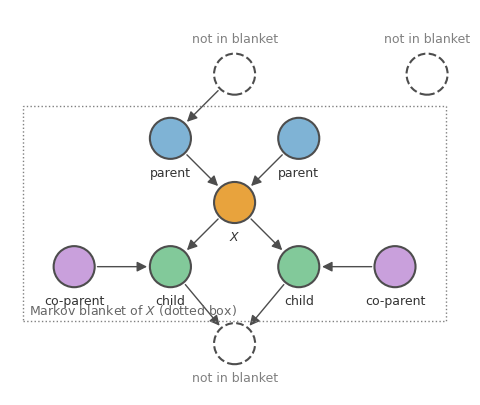

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Circle

pos = {'GP': (0.0, 3.0), 'P1': (-1.0, 2.0), 'P2': (1.0, 2.0), 'X': (0.0, 1.0),
       'C1': (-1.0, 0.0), 'C2': (1.0, 0.0), 'Q1': (-2.5, 0.0), 'Q2': (2.5, 0.0), 'D': (0.0, -1.2), 'U': (3.0, 3.0)}
edges = [('GP','P1'), ('P1','X'), ('P2','X'), ('X','C1'), ('X','C2'), ('Q1','C1'), ('Q2','C2'), ('C1','D'), ('C2','D')]
role = {'X': 'X', 'P1': 'parent', 'P2': 'parent', 'C1': 'child', 'C2': 'child', 'Q1': 'co-parent', 'Q2': 'co-parent'}
colour = {'X': '#e8a33d', 'parent': '#7fb3d5', 'child': '#82c99a', 'co-parent': '#c9a0dc'}
label = {'X': '$X$', 'P1': 'parent', 'P2': 'parent', 'C1': 'child', 'C2': 'child', 'Q1': 'co-parent', 'Q2': 'co-parent',
         'GP': 'not in blanket', 'D': 'not in blanket', 'U': 'not in blanket'}

fig, ax = plt.subplots(figsize=(8, 5))
r = 0.32
for a, b in edges:
    (x0, y0), (x1, y1) = pos[a], pos[b]
    d = np.hypot(x1 - x0, y1 - y0)
    ax.add_patch(FancyArrowPatch((x0 + (x1-x0)*r/d, y0 + (y1-y0)*r/d), (x1 - (x1-x0)*r/d, y1 - (y1-y0)*r/d),
                                 arrowstyle='-|>', mutation_scale=15, color='0.3'))
for n, (x, y) in pos.items():
    ax.add_patch(Circle((x, y), r, facecolor=colour.get(role.get(n), 'white'), edgecolor='0.3', lw=1.5, ls='-' if n in role else '--'))
    if n in ('GP', 'U'):
        ax.text(x, y + r + 0.12, label[n], ha='center', va='bottom', fontsize=9, color='0.5')
    else:
        ax.text(x, y - r - 0.12, label[n], ha='center', va='top', fontsize=9, color='0.2' if n in role else '0.5')
ax.add_patch(plt.Rectangle((-3.3, -0.85), 6.6, 3.35, fill=False, ls=':', ec='0.5'))
ax.text(-3.2, -0.8, 'Markov blanket of $X$ (dotted box)', fontsize=9, color='0.4', va='bottom')
ax.set_xlim(-3.5, 3.5); ax.set_ylim(-2.0, 4.0); ax.set_aspect('equal'); ax.axis('off')
plt.show()

The Gibbs sampler is a Markov chain of the kind described above. Its transition probabilities are defined by the Markov blankets of the non-evidence variables, and the long-run fraction of time it spends in each state converges to that state's posterior probability (provided every state can be reached from every other, for example when no conditional probability is exactly zero). As before, the early samples are not drawn in proportion to their posterior probability because the initial state is arbitrary, so a *burn-in* period is discarded before counting.

We code it by hand for the careers network with evidence $F=0$ and $S=1$. The variable $G$ has no parents or children, so its blanket is empty and we sample it from $P(G)$. The variable $M$ has no parents, and children $F$ and $S$, so $P(M\vert\mathrm{mb}(M))\propto P(M)P(F=0\vert M)P(S=1\vert M)$.

In [ ]:
def gibbs(nsteps, state):
    trace = np.zeros((nsteps, 2), dtype=int)
    for t in range(nsteps):
        if rng.integers(2) == 0:                    # resample G from its (empty) Markov blanket
            state[0] = rng.binomial(1, PG[1])
        else:                                       # resample M given its Markov blanket (F=0, S=1)
            p = PM * PF_M[f_obs, :] * PS_M[s_obs, :]
            state[1] = rng.binomial(1, p[1] / p.sum())
        trace[t] = state
    return trace

trace_g = gibbs(50000, [0, 0])[1000:]               # discard burn-in
print(f"Gibbs: P(M=1 | F=0, S=1) = {trace_g[:, 1].mean():.4f}   (exact {exact_post[1]:.4f})")
print(f"Gibbs: P(G=1 | F=0, S=1) = {trace_g[:, 0].mean():.4f}   (exact 0.4000)")

Gibbs: P(M=1 | F=0, S=1) = 0.2083   (exact 0.2075)
Gibbs: P(G=1 | F=0, S=1) = 0.4040   (exact 0.4000)


Every proposed update is accepted, and the result agrees with the exact answer. Note that we never needed the normalising constant $P(F=0,S=1)$ of the posterior.

## Gibbs sampling in PyMC

Samplers for general networks are tedious to code by hand, and inefficient if implemented naively, so we normally use a library. We will use `pymc`. Note that PyMC does not provide a general-purpose Gibbs sampler. It provides a range of *step methods*: `Metropolis`, which proposes a random change to a variable and accepts or rejects it with a probability that depends on the ratio of the probabilities of the new and old states; `BinaryGibbsMetropolis` and `CategoricalGibbsMetropolis` for discrete variables, which update one variable at a time as in Gibbs sampling but use a Metropolis accept/reject step; and `NUTS` for continuous variables. All of these are MCMC methods with the same overall structure as the Gibbs sampler (initialise, burn in, count the states visited), so what we learn here applies to all of them. Let's build the network in PyMC. First, we need to install it. This is regrettably not as easy as we might like as there are some version conflicts with other packages.

1. In Anaconda Navigator, create a new environment called `pymc`.
2. Open a terminal in the new environment.
3. Enter the following commands
 - `conda update -n base conda`
 - `conda install -n base conda-libmamba-solver`
 - `conda config --set solver libmamba`
 - `conda install jupyter`
 - `conda install -c conda-forge "pymc>=5"`

In [ ]:
import pymc as mc

The model below is a direct translation of the factorisation $P(G)P(M)P(F\vert M)P(S\vert M)$ into PyMC, one line per factor. The parts are as follows.

* **`with mc.Model() as model:`** creates a container. Every random variable defined inside the `with` block is registered in `model`, and the model records which variables depend on which, so it is the PyMC version of the DAG.

* **Root nodes: `G` and `M`.** `mc.Bernoulli('G', p)` creates a binary random variable (values 0 and 1) with $P(G=1)=p$ and $P(G=0)=1-p$. The first argument is the name under which the samples appear in the trace, and the second is the probability of the value 1. Because our arrays are indexed in the same order as their names, with `PG[0]` for False and `PG[1]` for True, we pass `PG[1]`, which is $P(G=1)$. Only this one number is needed since the other is $1-p$. $G$ and $M$ have no parents, so their probabilities are fixed numbers: these are the prior distributions.

* **Child nodes: `F` and `S`.** Here the probability depends on the value of the parent $M$. The table `PF_M[f][m]` gives $P(F=f\vert M=m)$, so we need
$P(F=1\vert M=0)=\texttt{PF\_M[1,0]}=0.2$ if $M=0$ and $P(F=1\vert M=1)=\texttt{PF\_M[1,1]}=0.6$ if $M=1$.
  We cannot just write `PF_M[1, M]`, because `M` is not a number: it is a random variable whose value is different in every sample, and PyMC has to build an *expression* that is re-evaluated whenever `M` changes. Two pieces make this possible.
    * `mc.math.switch(cond, a, b)` is an "if-else" for such expressions: it returns `a` when `cond` is true (non-zero) and `b` otherwise. So `mc.math.switch(M, PF_M[1,1], PF_M[1,0])` returns $P(F=1\vert M=1)$ when $M=1$ and $P(F=1\vert M=0)$ when $M=0$. This is how a row or column of a conditional probability table is *selected* by the value of the parent.
    * `mc.Deterministic('P_F', expression)` gives a name to a quantity that is *computed* from other variables rather than sampled. It adds no randomness: `P_F` is always exactly 0.2 or 0.6, determined by `M`. Naming it means that it is stored in the trace alongside the random variables, so we can inspect it.

  Finally `F = mc.Bernoulli('F', P_F)` says that $F$ is a binary random variable whose probability of being 1 is `P_F`. The chain of dependence $M\to$ `P_F` $\to F$ is the edge $M\to F$ of the DAG. The lines for `P_S` and `S` do the same for $S$ with the table `PS_M`. In networks where a variable has several parents, `switch` has to be nested, as we see in the next section.

* **Sampling.** `mc.Metropolis()` selects the step method (the MCMC rule used to update the variables, as in the previous section). `mc.sample(10000, ...)` runs the chain: `tune=5000` is the burn-in, 5,000 initial steps that are discarded, and `10000` is the number of samples kept. The `random_seed` makes the run reproducible and `progressbar` just displays progress. By default PyMC runs several chains from different starting points, which lets us check convergence.

No evidence has been supplied, so the sampler explores the full joint distribution $P(G,M,F,S)$.

In [ ]:
with mc.Model() as model:
    G = mc.Bernoulli('G',PG[1])
    M = mc.Bernoulli('M',PM[1])
    P_F = mc.Deterministic('P_F', mc.math.switch(M,PF_M[1,1],PF_M[1,0]))
    F = mc.Bernoulli('F', P_F)
    P_S = mc.Deterministic('P_S', mc.math.switch(M,PS_M[1,1],PS_M[1,0]))
    S = mc.Bernoulli('S',P_S)
    step = mc.Metropolis()
    trace = mc.sample(10000, step=step, tune=5000, random_seed=123, progressbar=True)

Multiprocess sampling (2 chains in 2 jobs)


CompoundStep


>Metropolis: [G]


>Metropolis: [M]


>Metropolis: [F]


>Metropolis: [S]


/sessions/dreamy-dazzling-bohr/.local/lib/python3.10/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 2 chains for 5_000 tune and 10_000 draw iterations (10_000 + 20_000 draws total) took 2 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


array([[<Axes: title={'center': 'G'}>, <Axes: title={'center': 'G'}>],
       [<Axes: title={'center': 'M'}>, <Axes: title={'center': 'M'}>],
       [<Axes: title={'center': 'F'}>, <Axes: title={'center': 'F'}>],
       [<Axes: title={'center': 'S'}>, <Axes: title={'center': 'S'}>],
       [<Axes: title={'center': 'P_F'}>, <Axes: title={'center': 'P_F'}>],
       [<Axes: title={'center': 'P_S'}>, <Axes: title={'center': 'P_S'}>]],
      dtype=object)

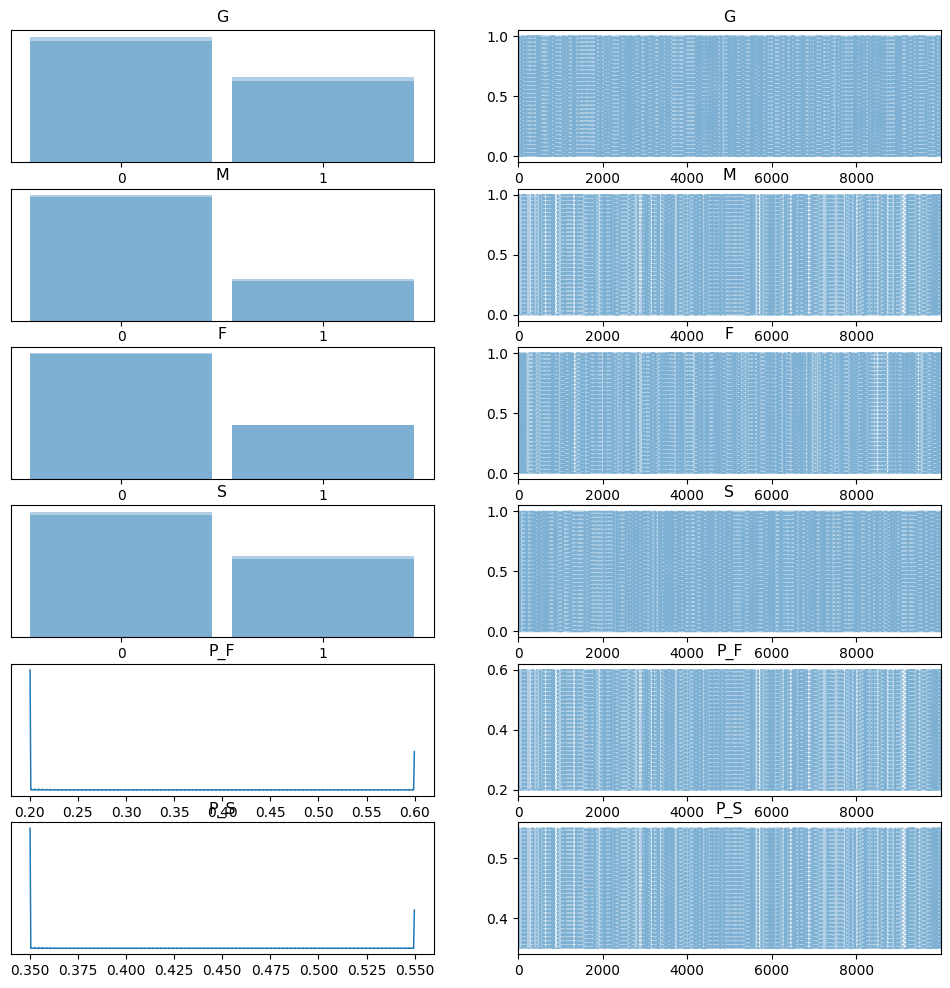

In [ ]:
mc.plot_trace(trace)

In [ ]:
for t in trace.posterior:
  print(t)

G
M
F
S
P_F
P_S


In [ ]:
df=trace.to_dataframe(groups='posterior')
print(df)

       chain  draw  G  M  F  S  P_F   P_S
0          0     0  0  0  0  0  0.2  0.35
1          0     1  0  0  1  1  0.2  0.35
2          0     2  0  0  1  0  0.2  0.35
3          0     3  0  0  0  0  0.2  0.35
4          0     4  0  0  0  0  0.2  0.35
...      ...   ... .. .. .. ..  ...   ...
19995      1  9995  0  0  0  0  0.2  0.35
19996      1  9996  0  0  0  0  0.2  0.35
19997      1  9997  1  0  0  0  0.2  0.35
19998      1  9998  1  0  1  0  0.2  0.35
19999      1  9999  1  1  0  1  0.6  0.55

[20000 rows x 8 columns]


In [ ]:
P_Math_Finance = float(df[(df['F'] == 1) & (df['M'] ==1)].shape[0]) / df[df['F'] == 1].shape[0]
print(P_Math_Finance)

0.482017982017982


Notice that in the model above we did not specify any evidence, so the sampler has simply explored the full joint distribution. We obtained a conditional probability by filtering the rows of the trace *afterwards*, which is equivalent to rejection sampling applied to the output of an MCMC sampler. To make the sampler work in the way described above, with the evidence variables fixed, we declare them as `observed`. Here we fix $F=1$ and estimate $P(M\vert F=1)$, which we calculated exactly in the previous section to be $0.5$.

In [ ]:
with mc.Model() as model_obs:
    G = mc.Bernoulli('G',PG[1])
    M = mc.Bernoulli('M',PM[1])
    P_F = mc.Deterministic('P_F', mc.math.switch(M,PF_M[1,1],PF_M[1,0]))
    F = mc.Bernoulli('F', P_F, observed=1)       # Evidence: F=1
    P_S = mc.Deterministic('P_S', mc.math.switch(M,PS_M[1,1],PS_M[1,0]))
    S = mc.Bernoulli('S',P_S)
    trace_obs = mc.sample(10000, tune=5000, random_seed=123, progressbar=False)

print(f"P(M=1|F=1) = {float(trace_obs.posterior['M'].mean())} (expected 0.5)")

Multiprocess sampling (2 chains in 2 jobs)


BinaryGibbsMetropolis: [G, M, S]


Sampling 2 chains for 5_000 tune and 10_000 draw iterations (10_000 + 20_000 draws total) took 1 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


P(M=1|F=1) = 0.49685 (expected 0.5)
